# MODELO PARA LA CLASIFICACIÓN DE MICROESTRUCTURAS BAINITÍCAS

## ResNet50

In [ ]:
import os
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from PIL import Image
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             classification_report, confusion_matrix)

SEED = 42
tf.keras.utils.set_random_seed(SEED)


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## Extración y organización de datos


TRAIN
i                           : 316
ii                          : 310
iii                         : 306

TEST
i                           : 198
ii                          : 102
iii                         : 86

Ejemplo: 10-400-01-H-12mm-4000x14_1_1.png | Tamaño: (768, 768) | Modo: P


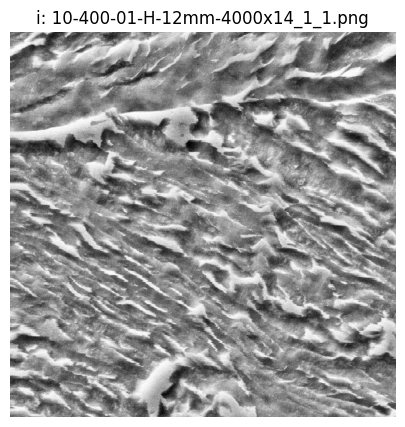

In [ ]:
RUTA_BASE = '/content/drive/MyDrive/Colab Notebooks/IA/IA II/Proyecto IA2/Bainitic Microstructures'
RUTA_TRAIN = os.path.join(RUTA_BASE, 'im_train')
RUTA_TEST = os.path.join(RUTA_BASE, 'testset')  # carpeta de prueba real en tu notebook
EXTENSIONES = ('.png',)
CLASES_EXCLUIDAS = []

for nombre, carpeta_raiz in [('TRAIN', RUTA_TRAIN), ('TEST', RUTA_TEST)]:
    if not os.path.isdir(carpeta_raiz):
        raise FileNotFoundError(f'No existe {carpeta_raiz}. Revisa el nombre en Drive.')
    print(f'\n{nombre}')
    for clase in sorted(os.listdir(carpeta_raiz)):
        carpeta = os.path.join(carpeta_raiz, clase)
        if os.path.isdir(carpeta) and not clase.startswith('.'):
            cantidad = sum(f.lower().endswith(EXTENSIONES) for f in os.listdir(carpeta))
            print(f'{clase:28s}: {cantidad}')

# Ejemplo de imagen original (sin redimensionar)
carpetas = [c for c in sorted(os.listdir(RUTA_TRAIN))
            if os.path.isdir(os.path.join(RUTA_TRAIN, c)) and not c.startswith('.')]
clase_ejemplo = carpetas[0]
archivos = [f for f in os.listdir(os.path.join(RUTA_TRAIN, clase_ejemplo))
            if f.lower().endswith(EXTENSIONES)]
if not archivos:
    raise ValueError(f'No hay imágenes PNG en {clase_ejemplo}')
ejemplo = archivos[0]
img = Image.open(os.path.join(RUTA_TRAIN, clase_ejemplo, ejemplo))
print(f'\nEjemplo: {ejemplo} | Tamaño: {img.size} | Modo: {img.mode}')
plt.figure(figsize=(7, 5))
plt.imshow(img.convert('L'), cmap='gray')
plt.title(f'{clase_ejemplo}: {ejemplo}')
plt.axis('off')
plt.show()

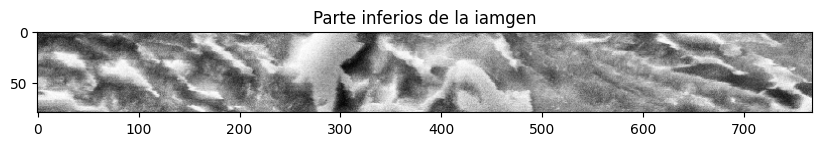

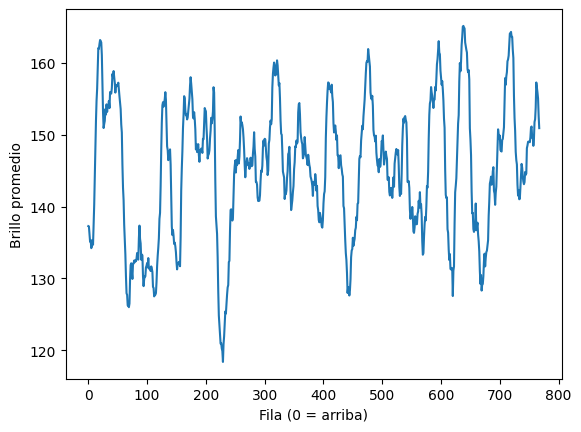

In [ ]:
arr = np.array(img.convert("L"))
plt.figure(figsize=(10,3))
plt.imshow(arr[-80:,:], cmap="gray")
plt.title("Parte inferios de la iamgen")
plt.show()

# Brillo promedio por fila: la franja suele verse como un salto brusco
plt.plot(arr.mean(axis=1))
plt.xlabel("Fila (0 = arriba)")
plt.ylabel("Brillo promedio")
plt.show()

In [ ]:
def inventariar(ruta_raiz):
    filas = []
    for clase in sorted(os.listdir(ruta_raiz)):
        carpeta = os.path.join(ruta_raiz, clase)
        if not os.path.isdir(carpeta) or clase.startswith('.') or clase in CLASES_EXCLUIDAS:
            continue
        for archivo in sorted(os.listdir(carpeta)):
            if archivo.lower().endswith(EXTENSIONES):
                filas.append({'ruta': os.path.join(carpeta, archivo), 'clase': clase})
    if not filas:
        raise ValueError(f'No se encontraron imágenes en {ruta_raiz}')
    return pd.DataFrame(filas)

df_train_original = inventariar(RUTA_TRAIN)
df_test_original = inventariar(RUTA_TEST)
clases = sorted(df_train_original['clase'].unique().tolist())
clase_a_id = {clase: i for i, clase in enumerate(clases)}

clases_desconocidas = set(df_test_original['clase']) - set(clases)
if clases_desconocidas:
    raise ValueError(f'Clases en test que no aparecen en train: {clases_desconocidas}')

for tabla in (df_train_original, df_test_original):
    tabla['label'] = tabla['clase'].map(clase_a_id).astype('int32')

print('Clases:', clases)
print('Original train:', len(df_train_original), '| Test reservado:', len(df_test_original))
print('\nTrain original por clase:\n', df_train_original['clase'].value_counts())
print('\nTest por clase:\n', df_test_original['clase'].value_counts())

Clases: ['i', 'ii', 'iii']
Original train: 932 | Test reservado: 386

Train original por clase:
 clase
i      316
ii     310
iii    306
Name: count, dtype: int64

Test por clase:
 clase
i      198
ii     102
iii     86
Name: count, dtype: int64


In [ ]:
# 80 % de im_train para entrenamiento, 20 % para validación.
# testset se reserva completo para evaluar al final.
train_df, val_df = train_test_split(
    df_train_original, test_size=0.20,
    stratify=df_train_original['label'], random_state=SEED
)
test_df = df_test_original.copy()
train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

resumen = pd.concat({
    'train': train_df['clase'].value_counts(),
    'validation': val_df['clase'].value_counts(),
    'test': test_df['clase'].value_counts()
}, axis=1).fillna(0).astype(int)
print(resumen)
print('Totales:', resumen.sum().to_dict())
for a, b in [(train_df, val_df), (train_df, test_df), (val_df, test_df)]:
    assert set(a['ruta']).isdisjoint(set(b['ruta'])), 'Se repitió una ruta entre conjuntos'
print('Sin rutas compartidas entre train, validation y test.')
# Nota: esta comprobación no detecta recortes de una misma micrografía ni duplicados visuales.

       train  validation  test
clase                         
i        252          64   198
ii       248          62   102
iii      245          61    86
Totales: {'train': 745, 'validation': 187, 'test': 386}
Sin rutas compartidas entre train, validation y test.


### Comprobaciones antes del entrenamiento
La partición de validación procede solo de `im_train`; `testset` queda reservado para la evaluación final. La separación por **ruta** no detecta duplicados visuales ni parches procedentes de una misma micrografía. Si hay imágenes relacionadas, la separación correcta requiere agruparlas por muestra original.

In [ ]:
print("Correspondencia de etiquetas:", clase_a_id)
print("Proporciones por conjunto:")
print(pd.DataFrame({
    "train": train_df["clase"].value_counts(normalize=True),
    "validation": val_df["clase"].value_counts(normalize=True),
    "test": test_df["clase"].value_counts(normalize=True)
}).round(3))
assert len(clases) >= 2, "Se requieren al menos dos clases para clasificar."
assert len(train_df) and len(val_df) and len(test_df), "Alguna partición está vacía."

Correspondencia de etiquetas: {'i': 0, 'ii': 1, 'iii': 2}
Proporciones por conjunto:
       train  validation   test
clase                          
i      0.338       0.342  0.513
ii     0.333       0.332  0.264
iii    0.329       0.326  0.223


Lote: (32, 224, 224, 1) (32,)


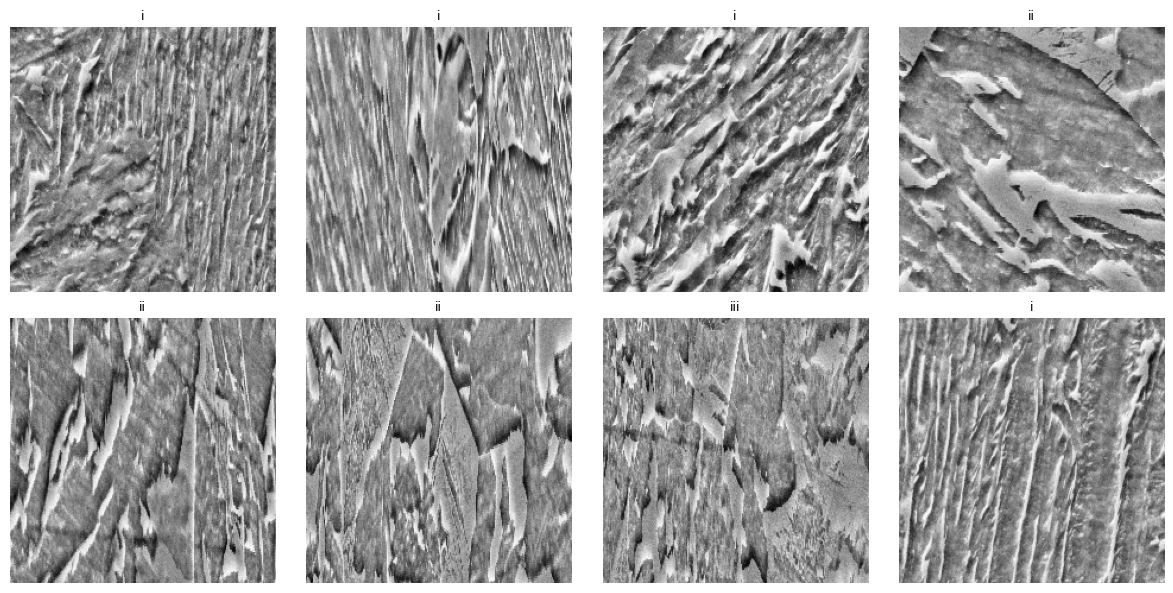

In [ ]:
IMG_SIZE = 224
FILAS_UTILES = 481  # misma decisión de recorte del notebook original
BATCH = 32
AUTOTUNE = tf.data.AUTOTUNE

def cargar_imagen(ruta, label):
    contenido = tf.io.read_file(ruta)
    img = tf.image.decode_png(contenido, channels=1)
    img = img[:FILAS_UTILES, :, :]
    img = tf.image.resize(img, [IMG_SIZE, IMG_SIZE])
    img = tf.cast(img, tf.float32)  # rango aproximado 0-255 para ResNet50
    return img, tf.cast(label, tf.int32)

def crear_dataset(tabla, entrenamiento=False):
    ds = tf.data.Dataset.from_tensor_slices(
        (tabla['ruta'].values, tabla['label'].values.astype('int32')))
    ds = ds.map(cargar_imagen, num_parallel_calls=AUTOTUNE)
    # Evita mantener tres copias completas en RAM si el dataset es grande.
    if entrenamiento:
        ds = ds.shuffle(len(tabla), seed=SEED, reshuffle_each_iteration=True)
    return ds.batch(BATCH).prefetch(AUTOTUNE)

train_ds = crear_dataset(train_df, entrenamiento=True)
val_ds = crear_dataset(val_df)
test_ds = crear_dataset(test_df)  # NO shuffle: orden idéntico a test_df
imgs, labs = next(iter(train_ds))
print('Lote:', imgs.shape, labs.shape)
plt.figure(figsize=(12, 6))
for i in range(min(8, len(imgs))):
    plt.subplot(2, 4, i + 1)
    plt.imshow(imgs[i].numpy().squeeze(), cmap='gray')
    plt.title(clases[int(labs[i])], fontsize=9)
    plt.axis('off')
plt.tight_layout()
plt.show()

## **AUMENTO DE DATOS**

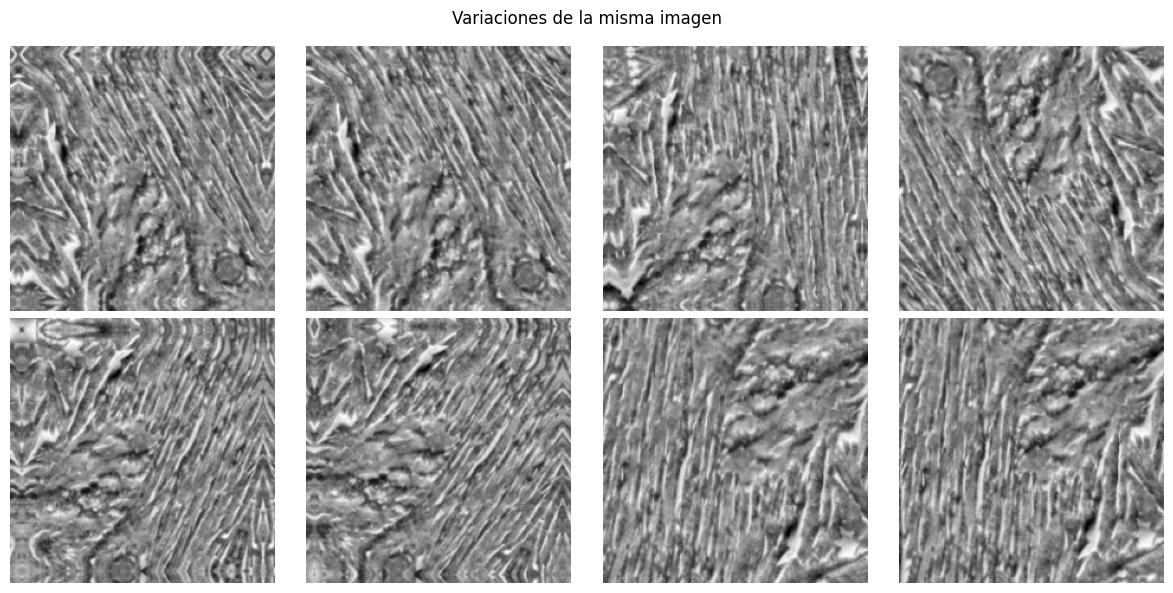

In [ ]:
from tensorflow.keras import layers

data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.1, fill_mode="reflect"),
    layers.RandomZoom(0.1, fill_mode="reflect"),
    layers.RandomContrast(0.10),
], name="augmentation")

# Ver cómo transforma UNA imagen
img = imgs[0:1]
plt.figure(figsize=(12, 6))
for k in range(8):
    aumentada = data_augmentation(img, training=True)
    plt.subplot(2, 4, k + 1)
    plt.imshow(aumentada[0].numpy().squeeze(), cmap="gray")
    plt.axis("off")
plt.suptitle("Variaciones de la misma imagen")
plt.tight_layout(); plt.show()

In [ ]:
from sklearn.utils.class_weight import compute_class_weight

pesos = compute_class_weight(
    class_weight='balanced', classes=np.arange(len(clases)), y=train_df['label'].to_numpy())
class_weight = {i: float(p) for i, p in enumerate(pesos)}
for i, clase in enumerate(clases):
    print(f'{clase:28s} peso = {class_weight[i]:.3f}')

i                            peso = 0.985
ii                           peso = 1.001
iii                          peso = 1.014


In [ ]:
def crear_resnet50(n_clases):
    entradas = layers.Input(shape=(IMG_SIZE, IMG_SIZE, 1))
    x = data_augmentation(entradas)
    # ResNet50 de ImageNet espera tres canales con escala 0-255.
    x = layers.Concatenate(axis=-1)([x, x, x])
    x = layers.Lambda(
        tf.keras.applications.resnet50.preprocess_input,
        name="preprocesamiento_resnet50"
    )(x)

    base = tf.keras.applications.ResNet50(
        include_top=False, weights="imagenet",
        input_shape=(IMG_SIZE, IMG_SIZE, 3)
    )
    base.trainable = False
    x = base(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    # Cabezal más sencillo para reducir el sobreajuste observado.
    x = layers.Dense(256, activation="relu",
                     kernel_regularizer=tf.keras.regularizers.l2(1e-4))(x)
    x = layers.Dropout(0.5)(x)
    salidas = layers.Dense(n_clases, activation="softmax")(x)
    return tf.keras.Model(entradas, salidas, name="resnet50_bainita")

modelo = crear_resnet50(len(clases))
modelo.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)
modelo.summary(expand_nested=False)

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "resnet50_bainita"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 1)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ augmentation        │ (None, 224, 224,  │          0 │ input_layer_1[0]… │
│ (Sequential)        │ 1)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 224, 224,  │          0 │ augmentation[0][… │
│ (Concatenate)       │ 3)                │            │ augmentation[0][… │
│                     │                   │            │ augmentation[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ preprocesamiento_r… │ (None, 224, 224,  │          0 │ concatenate[0][0] │
│ (Lambda)            │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ resnet50            │ (None, 7, 7,      │ 23,587,712 │ preprocesamiento… │
│ (Functional)        │ 2048)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 2048)      │          0 │ resnet50[0][0]    │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 256)       │    524,544 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 256)       │          0 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 3)         │        771 │ dropout[0][0]     │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 24,113,027 (91.98 MB)

 Trainable params: 525,315 (2.00 MB)

 Non-trainable params: 23,587,712 (89.98 MB)

In [ ]:
# Los resultados previos mostraron confusión i -> ii. Como primera prueba,
# NO compensamos las clases automáticamente: los pesos pueden alterar
# fuertemente el equilibrio entre precisión y recall de cada clase.
USAR_PESOS_CLASE = False

callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=10, min_delta=0.001,
        restore_best_weights=True, verbose=1
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss", factor=0.5, patience=4,
        min_lr=1e-6, verbose=1
    ),
]

historia = modelo.fit(
    train_ds,
    validation_data=val_ds,
    epochs=100,
    callbacks=callbacks,
    class_weight=class_weight if USAR_PESOS_CLASE else None
)
print("Mejor val_loss:", min(historia.history["val_loss"]))

Epoch 1/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 49s 1s/step - accuracy: 0.4765 - loss: 1.3610 - val_accuracy: 0.6898 - val_loss: 0.7213 - learning_rate: 1.0000e-04
Epoch 2/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 22s 363ms/step - accuracy: 0.6671 - loss: 0.7668 - val_accuracy: 0.8075 - val_loss: 0.5025 - learning_rate: 1.0000e-04
Epoch 3/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 22s 360ms/step - accuracy: 0.6926 - loss: 0.6936 - val_accuracy: 0.8449 - val_loss: 0.4500 - learning_rate: 1.0000e-04
Epoch 4/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 21s 333ms/step - accuracy: 0.7691 - loss: 0.5721 - val_accuracy: 0.8824 - val_loss: 0.3968 - learning_rate: 1.0000e-04
Epoch 5/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 42s 366ms/step - accuracy: 0.8081 - loss: 0.5149 - val_accuracy: 0.8610 - val_loss: 0.3819 - learning_rate: 1.0000e-04
Epoch 6/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 40s 339ms/step - accuracy: 0.8309 - loss: 0.4661 - val_accuracy: 0.8770 - val_loss: 0.3721 - learning_rate: 1.0000e-04
Epoch 7/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 19s 282ms/step -

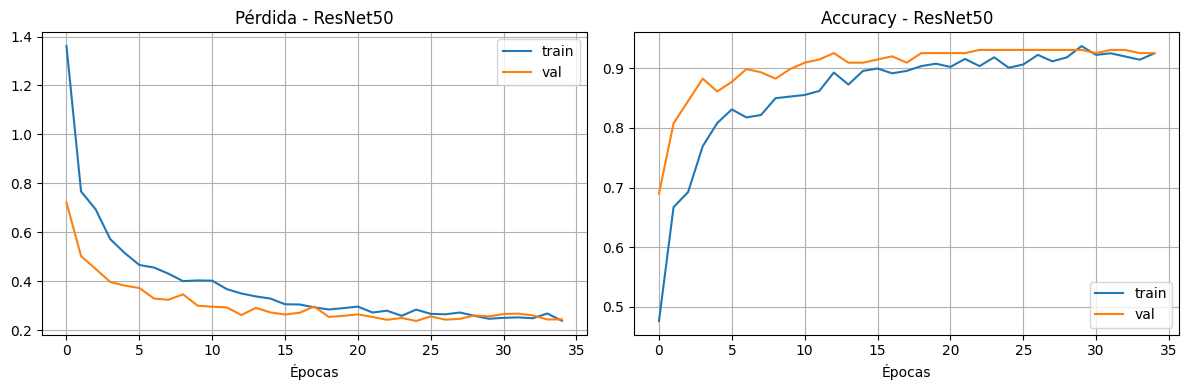

Mejor accuracy de validación: 0.9304812550544739
Menor pérdida de validación: 0.2372410148382187


In [ ]:

h = historia.history

fig, ax = plt.subplots(1, 2, figsize=(12, 4))

ax[0].plot(h["loss"], label="train")
ax[0].plot(h["val_loss"], label="val")
ax[0].set_title("Pérdida - ResNet50")
ax[0].set_xlabel("Épocas")
ax[0].legend()
ax[0].grid(True)

ax[1].plot(h["accuracy"], label="train")
ax[1].plot(h["val_accuracy"], label="val")
ax[1].set_title("Accuracy - ResNet50")
ax[1].set_xlabel("Épocas")
ax[1].legend()
ax[1].grid(True)

plt.tight_layout()
plt.show()

print("Mejor accuracy de validación:",
      max(h["val_accuracy"]))

print("Menor pérdida de validación:",
      min(h["val_loss"]))


Forma de los filtros: (7, 7, 3, 64)


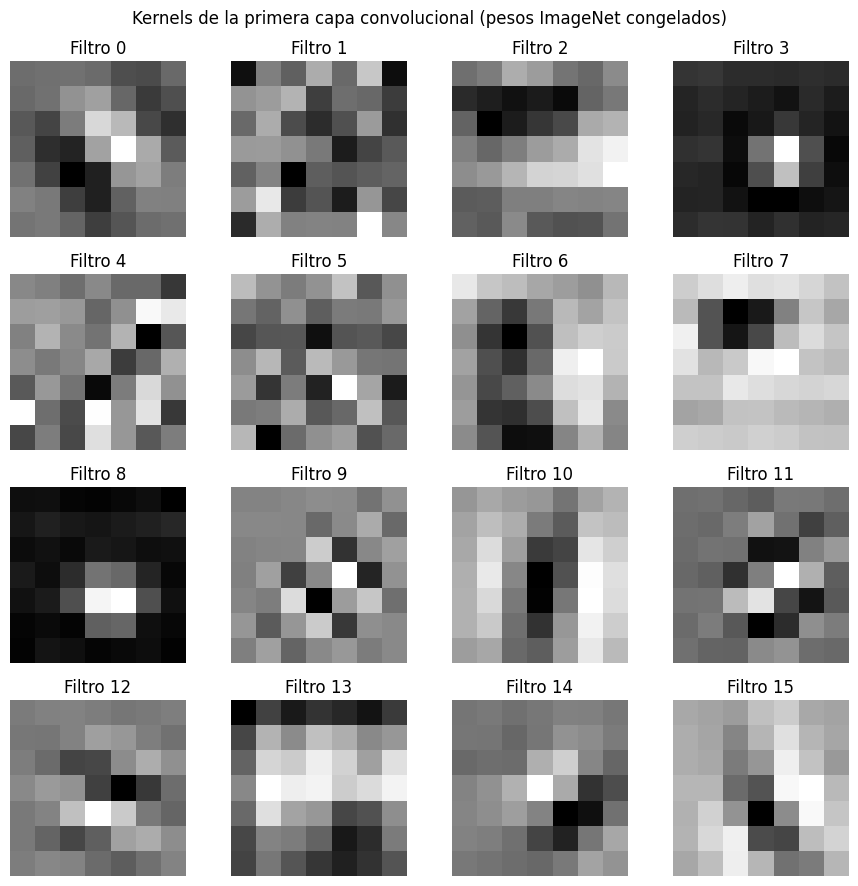

In [ ]:
# Pesos de los filtros de la primera convolución de ResNet50
base = modelo.get_layer('resnet50')
capa_filtros = base.get_layer('conv1_conv')
kernels = capa_filtros.get_weights()[0]  # (7, 7, 3, 64)
print('Forma de los filtros:', kernels.shape)

n_filtros = min(16, kernels.shape[-1])
fig, ejes = plt.subplots(4, 4, figsize=(9, 9))
for j, ax in enumerate(ejes.flat):
    if j < n_filtros:
        filtro = kernels[:, :, :, j].mean(axis=2)
        ax.imshow(filtro, cmap='gray')
        ax.set_title(f'Filtro {j}')
    ax.axis('off')
fig.suptitle('Kernels de la primera capa convolucional (pesos ImageNet congelados)')
plt.tight_layout()
plt.show()
# Como base.trainable=False, estos filtros provienen de ImageNet y NO se reajustan aquí.

In [ ]:

base = modelo.get_layer("resnet50")

capas_interes = [
    "conv1_relu",
    "conv2_block3_out",
    "conv3_block4_out",
    "conv4_block6_out",
    "conv5_block3_out"
]

modelo_activaciones = tf.keras.Model(
    inputs=base.input,
    outputs=[
        base.get_layer(nombre).output
        for nombre in capas_interes
    ]
)

print("CAPAS SELECCIONADAS")
print("-" * 55)

for nombre in capas_interes:
    capa = base.get_layer(nombre)
    print(nombre, capa.output.shape)


CAPAS SELECCIONADAS
-------------------------------------------------------
conv1_relu (None, 112, 112, 64)
conv2_block3_out (None, 56, 56, 256)
conv3_block4_out (None, 28, 28, 512)
conv4_block6_out (None, 14, 14, 1024)
conv5_block3_out (None, 7, 7, 2048)


In [ ]:
def preparar_para_base(ruta):
    # Igual recorte que el pipeline usado para entrenar/evaluar.
    img, _ = cargar_imagen(tf.constant(str(ruta)), tf.constant(0))
    img3 = tf.image.grayscale_to_rgb(img)
    img3 = tf.keras.applications.resnet50.preprocess_input(img3)
    return img, tf.expand_dims(img3, axis=0)

In [ ]:

def mostrar_activaciones(
    img_gris,
    activaciones,
    nombres,
    n_canales=16,
    titulo=""
):

    for nombre, act in zip(nombres, activaciones):

        act = act[0]

        # Promedio espacial por canal
        medias = act.mean(axis=(0, 1))

        # Seleccionar canales más activos
        top = np.argsort(medias)[::-1][:n_canales]

        total = len(top) + 1
        columnas = 5
        filas = math.ceil(total / columnas)

        plt.figure(figsize=(15, filas * 2.5))

        plt.subplot(filas, columnas, 1)
        plt.imshow(img_gris.numpy().squeeze(), cmap="gray")
        plt.title("Original", fontsize=9)
        plt.axis("off")

        for k, c in enumerate(top):

            plt.subplot(filas, columnas, k + 2)

            plt.imshow(
                act[:, :, c],
                cmap="viridis"
            )

            plt.title(
                f"Canal {c}",
                fontsize=8
            )

            plt.axis("off")

        plt.suptitle(
            f"{titulo} | {nombre} {act.shape}",
            fontsize=11
        )

        plt.tight_layout()
        plt.show()


Clase real: i

DIMENSIONES DE ACTIVACIONES
--------------------------------------------------
conv1_relu                (1, 112, 112, 64)
conv2_block3_out          (1, 56, 56, 256)
conv3_block4_out          (1, 28, 28, 512)
conv4_block6_out          (1, 14, 14, 1024)
conv5_block3_out          (1, 7, 7, 2048)


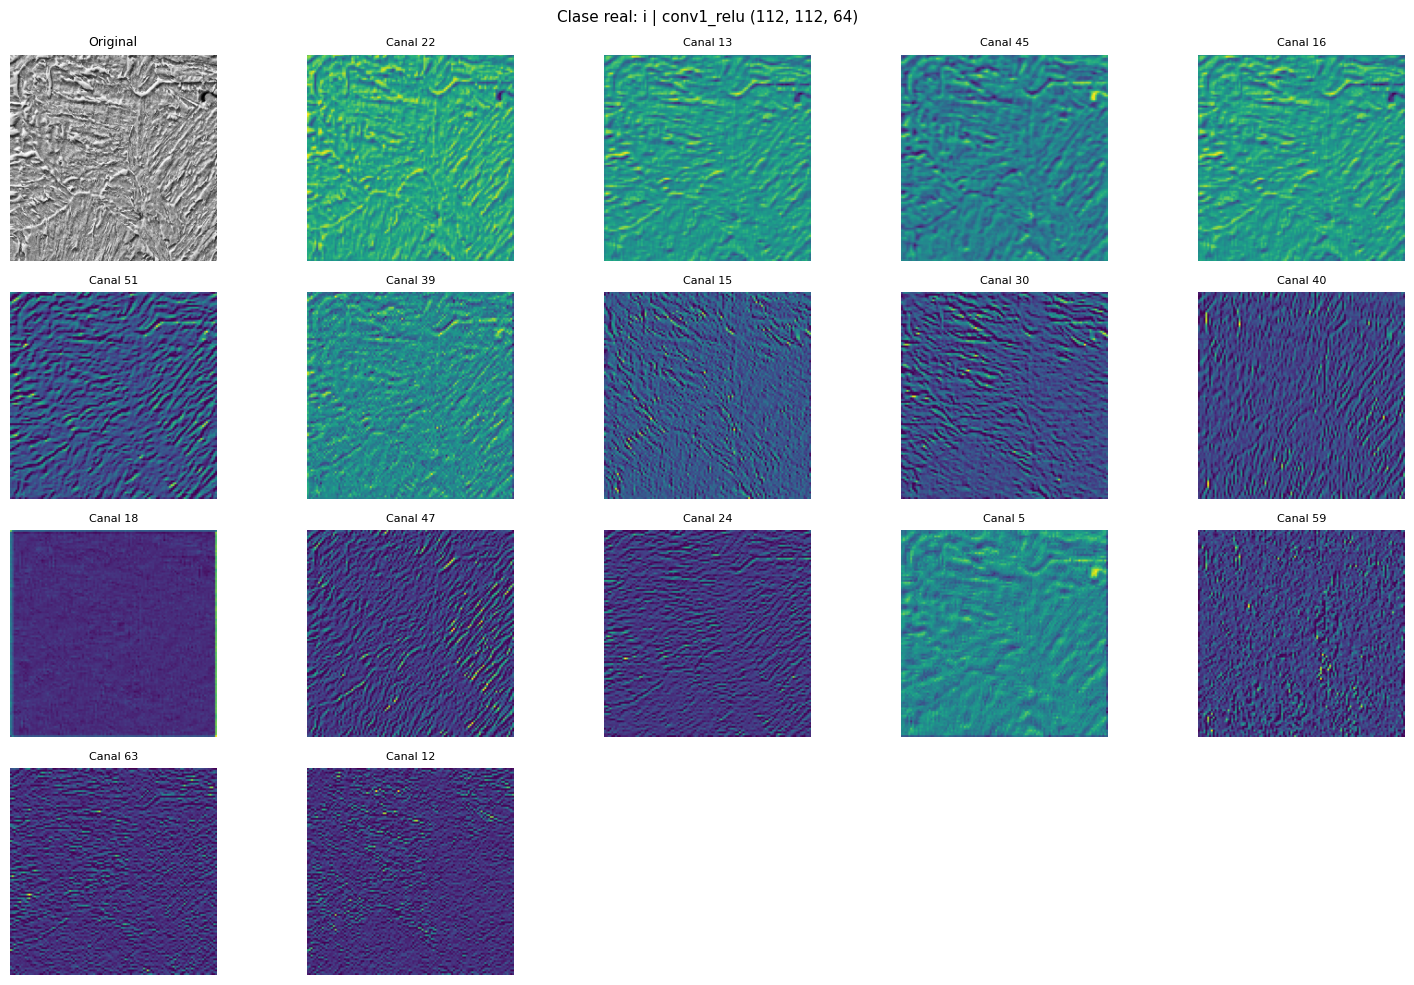

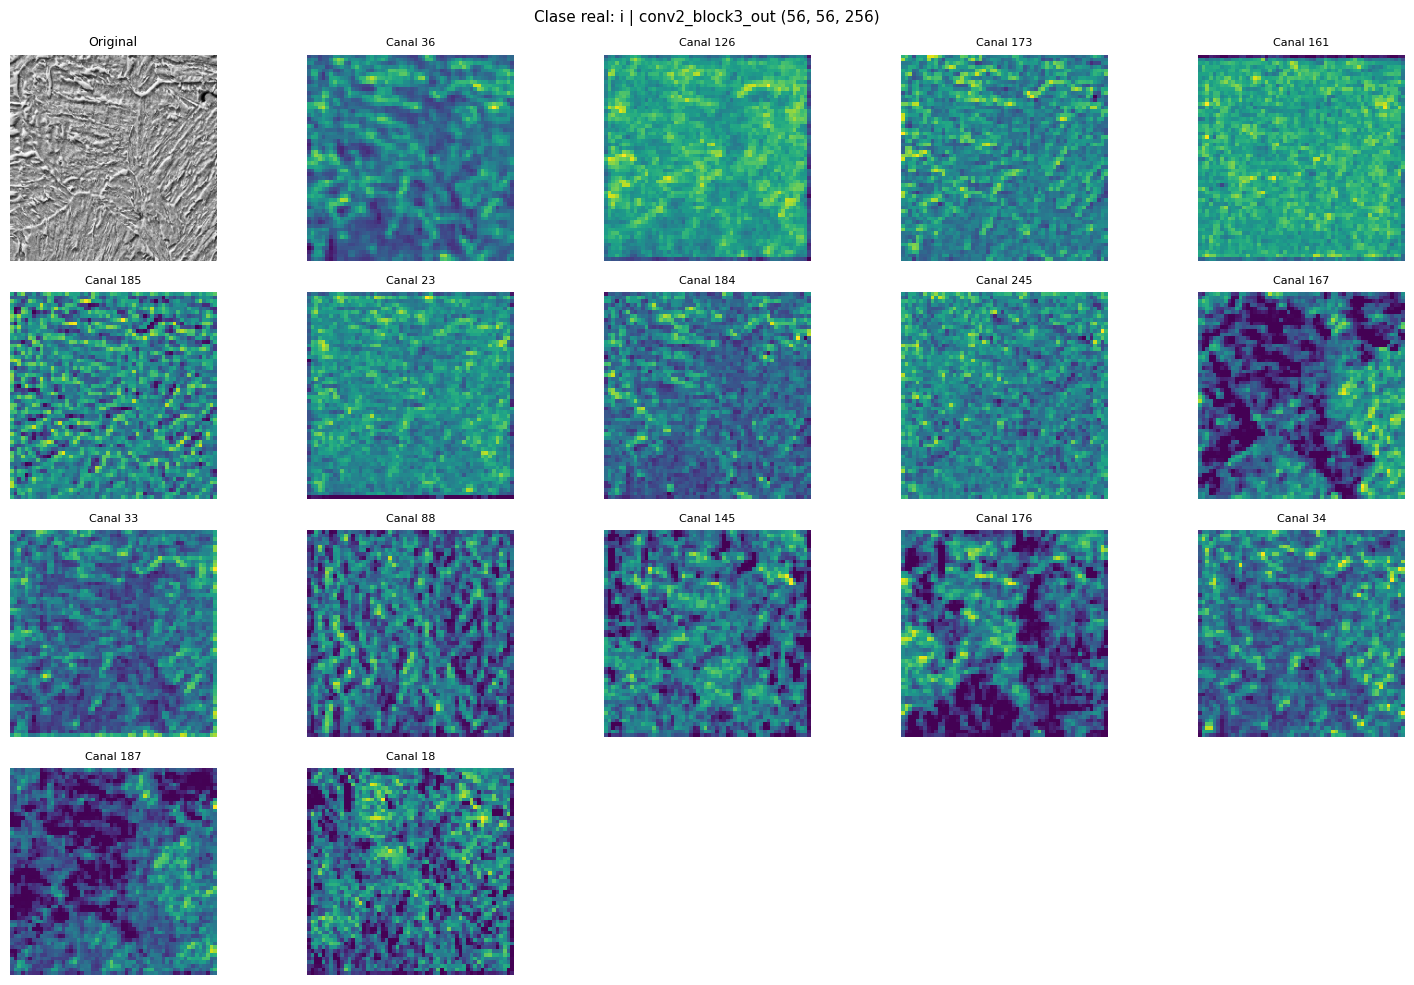

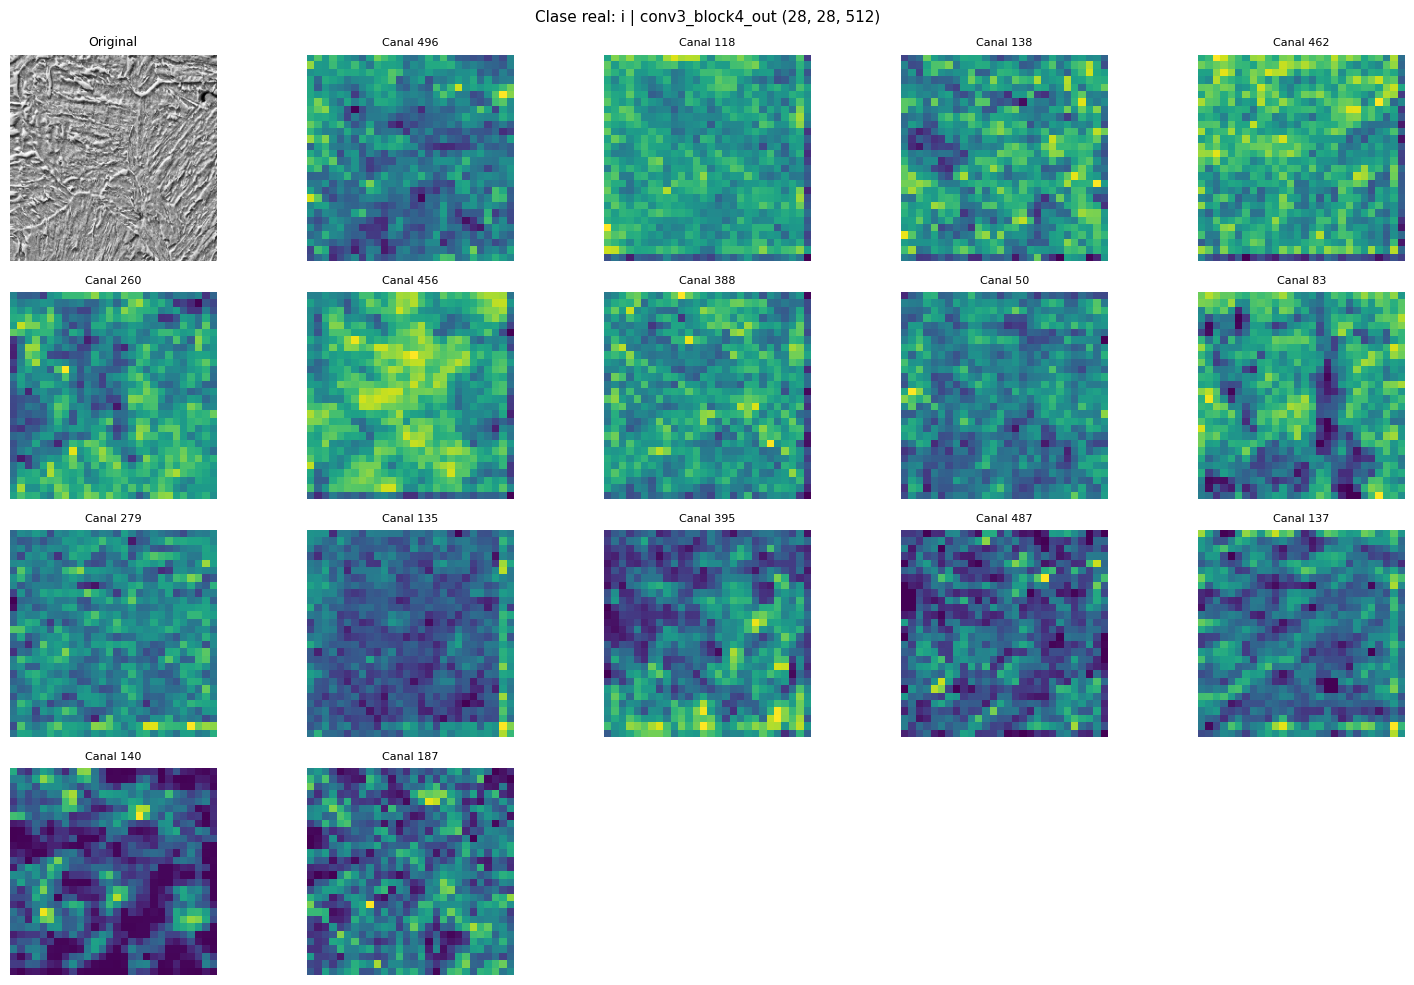

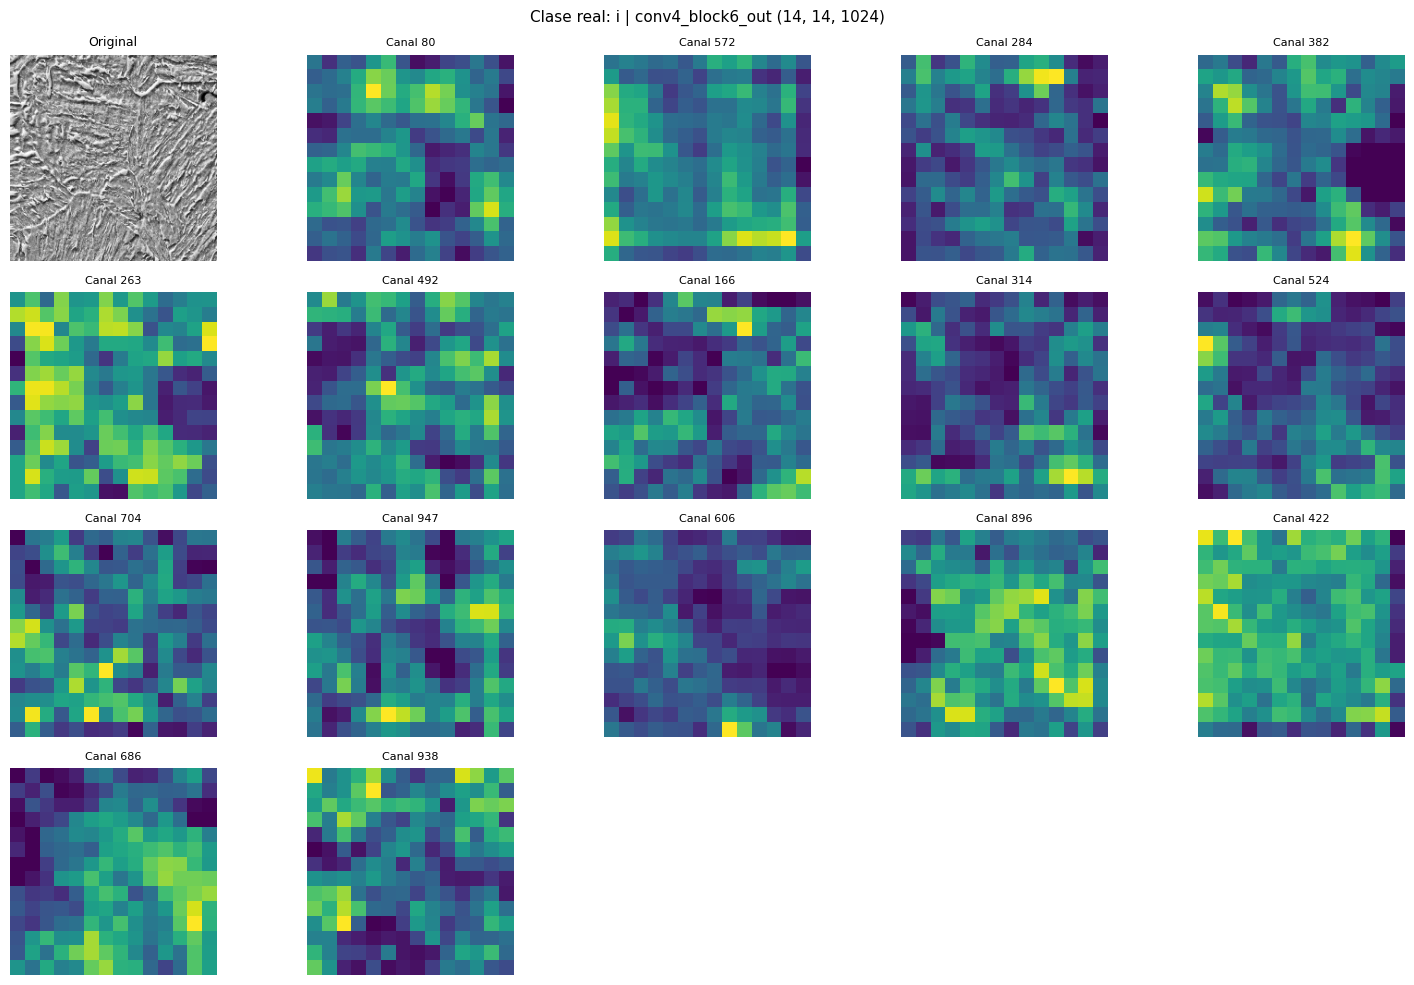

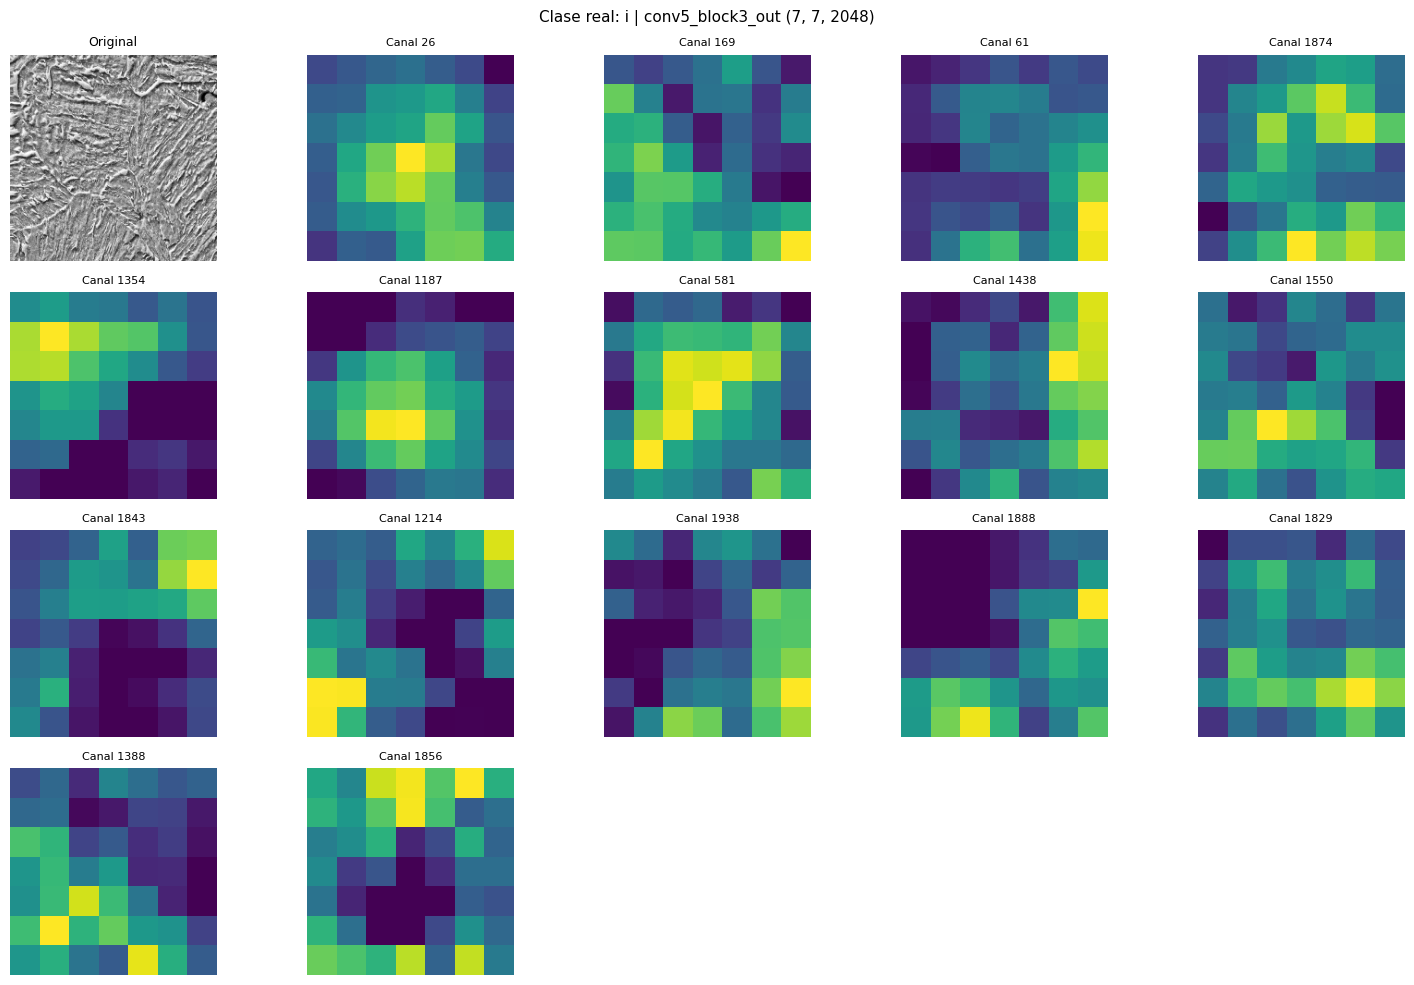

In [ ]:

ruta_ejemplo = test_df["ruta"].iloc[0]
clase_ejemplo = test_df["clase"].iloc[0]

img_gris, lote = preparar_para_base(ruta_ejemplo)

activaciones = modelo_activaciones.predict(
    lote,
    verbose=0
)

print("Clase real:", clase_ejemplo)
print("\nDIMENSIONES DE ACTIVACIONES")
print("-" * 50)

for nombre, act in zip(capas_interes, activaciones):
    print(f"{nombre:25s} {act.shape}")

mostrar_activaciones(
    img_gris,
    activaciones,
    capas_interes,
    n_canales=16,
    titulo=f"Clase real: {clase_ejemplo}"
)


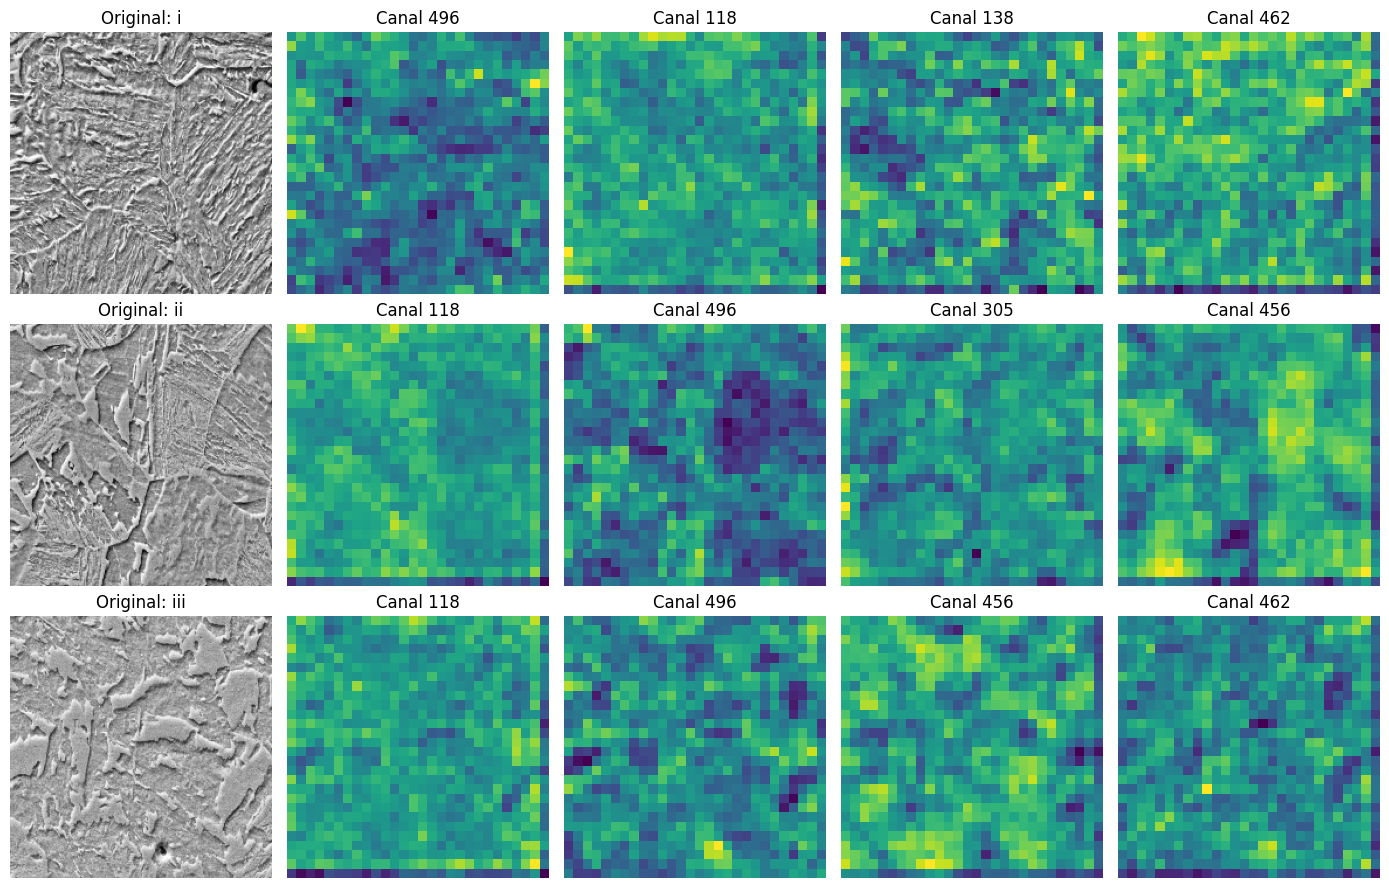

In [ ]:
capa_comparar = 'conv3_block4_out'
idx_capa = capas_interes.index(capa_comparar)
clases_disponibles = [cl for cl in clases if (test_df['clase'] == cl).any()]
plt.figure(figsize=(14, 3 * len(clases_disponibles)))
for f, cl in enumerate(clases_disponibles):
    ruta_clase = test_df.loc[test_df['clase'] == cl, 'ruta'].iloc[0]
    img_gris, lote = preparar_para_base(ruta_clase)
    act = modelo_activaciones.predict(lote, verbose=0)[idx_capa][0]
    top = np.argsort(act.mean(axis=(0, 1)))[::-1][:4]
    plt.subplot(len(clases_disponibles), 5, f * 5 + 1)
    plt.imshow(img_gris.numpy().squeeze(), cmap='gray')
    plt.title(f'Original: {cl}')
    plt.axis('off')
    for k, canal in enumerate(top):
        plt.subplot(len(clases_disponibles), 5, f * 5 + k + 2)
        plt.imshow(act[:, :, canal], cmap='viridis')
        plt.title(f'Canal {canal}')
        plt.axis('off')
plt.tight_layout()
plt.show()

In [ ]:

modelo.save("resnet50_bainita.keras")

print("Modelo guardado correctamente.")


Modelo guardado correctamente.


13/13 ━━━━━━━━━━━━━━━━━━━━ 56s 4s/step - accuracy: 0.6399 - loss: 0.6624
Métricas Keras: {'accuracy': 0.6398963928222656, 'loss': 0.662447988986969}
13/13 ━━━━━━━━━━━━━━━━━━━━ 7s 396ms/step
Accuracy:           0.6399
Precision macro:    0.7991
Recall macro:       0.6745
F1-score macro:    0.6506
Precision weighted: 0.8336
Recall weighted:    0.6399
F1-score weighted:  0.6536

Métricas por clase:
              precision    recall  f1-score   support

           i     0.9712    0.5101    0.6689       198
          ii     0.4262    0.9902    0.5959       102
         iii     1.0000    0.5233    0.6870        86

    accuracy                         0.6399       386
   macro avg     0.7991    0.6745    0.6506       386
weighted avg     0.8336    0.6399    0.6536       386



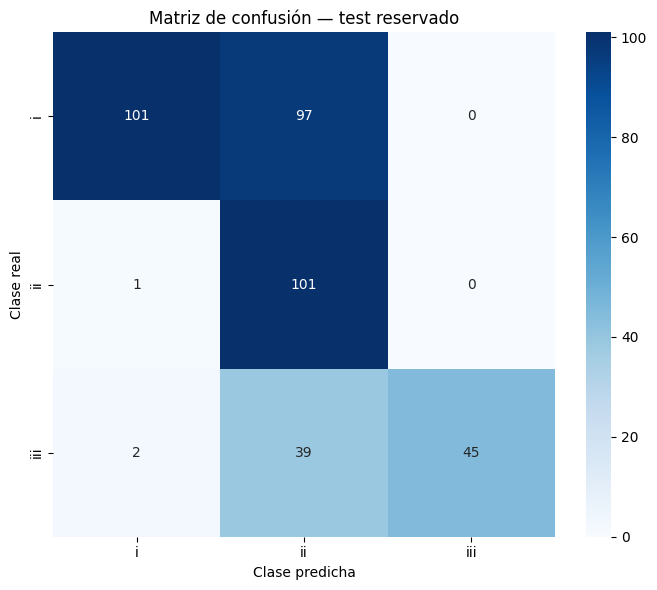

In [ ]:

# Evaluación únicamente sobre testset, nunca usado para ajustar el modelo.
resultados = modelo.evaluate(test_ds, verbose=1, return_dict=True)
print('Métricas Keras:', resultados)

y_real = test_df['label'].to_numpy()
probabilidades = modelo.predict(test_ds, verbose=1)
y_pred = np.argmax(probabilidades, axis=1)

accuracy = accuracy_score(y_real, y_pred)
precision_macro, recall_macro, f1_macro, _ = precision_recall_fscore_support(
    y_real, y_pred, labels=np.arange(len(clases)), average='macro', zero_division=0)
precision_weighted, recall_weighted, f1_weighted, _ = precision_recall_fscore_support(
    y_real, y_pred, labels=np.arange(len(clases)), average='weighted', zero_division=0)

print(f'Accuracy:           {accuracy:.4f}')
print(f'Precision macro:    {precision_macro:.4f}')
print(f'Recall macro:       {recall_macro:.4f}')
print(f'F1-score macro:    {f1_macro:.4f}')
print(f'Precision weighted: {precision_weighted:.4f}')
print(f'Recall weighted:    {recall_weighted:.4f}')
print(f'F1-score weighted:  {f1_weighted:.4f}')
print('\nMétricas por clase:')
print(classification_report(y_real, y_pred,
                            labels=np.arange(len(clases)), target_names=clases,
                            digits=4, zero_division=0))

matriz = confusion_matrix(y_real, y_pred, labels=np.arange(len(clases)))
plt.figure(figsize=(max(7, len(clases)), max(6, len(clases) * 0.8)))
sns.heatmap(matriz, annot=True, fmt='d', cmap='Blues',
            xticklabels=clases, yticklabels=clases)
plt.xlabel('Clase predicha')
plt.ylabel('Clase real')
plt.title('Matriz de confusión — test reservado')
plt.tight_layout()
plt.show()



In [ ]:
# Exportación opcional de predicciones y métricas de test
predicciones_test = test_df[['ruta', 'clase']].copy()
predicciones_test['clase_predicha'] = [clases[i] for i in y_pred]
predicciones_test['confianza'] = probabilidades.max(axis=1)
predicciones_test.to_csv('predicciones_resnet50_test.csv', index=False)
pd.DataFrame([{
    'accuracy': accuracy, 'precision_macro': precision_macro,
    'recall_macro': recall_macro, 'f1_macro': f1_macro,
    'precision_weighted': precision_weighted,
    'recall_weighted': recall_weighted, 'f1_weighted': f1_weighted
}]).to_csv('metricas_resnet50_test.csv', index=False)
print('CSV de predicciones y métricas guardados.')

CSV de predicciones y métricas guardados.


### Interpretación de resultados
Si persiste una caída grande entre validación y `testset`, inspecciona visualmente por clase el origen, iluminación, aumento, etiqueta y posible duplicación de micrografías. No cambies reiteradamente el modelo mirando el test reservado; utiliza validación para seleccionar hiperparámetros y deja el test para una evaluación final.